# Premier League Match Predictor

Run the cells in order. The notebook uses the same predictor as the CLI and API. Edit the club names and date under **Make a prediction**.

In [1]:
from dataclasses import asdict
from datetime import date, timedelta
from io import StringIO
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from predictor.data import DEFAULT_HISTORY, load_fixtures
from predictor.evaluation import (
    RETROSPECTIVE_START, backtest, backtest_csv, compare_market, select_model,
)
from predictor.market import MarketOdds
from predictor.model import FEATURE_NAMES, MODEL_LABELS, Predictor
from predictor.plots import calibration_plot
from predictor.scoreboard import DEFAULT_SCOREBOARD, logged_forecasts, read_scoreboard, scoreboard_csv
from predictor.season import (
    ScheduledMatch, forecast_season, load_schedule, official_history, official_schedule, season_csv, utc_now,
)

## Load and inspect the matches

In [2]:
DATA_FILE = DEFAULT_HISTORY
if not DATA_FILE.is_file():
    raise FileNotFoundError("Run python -m predictor refresh to download your local results first.")

matches = pd.read_csv(DATA_FILE)
matches.head()

,date,home_team,away_team,home_goals,away_goals,home_xg,away_xg,kickoff,referee,home_ht_goals,...,away_fouls,home_corners,away_corners,home_yellows,away_yellows,home_reds,away_reds,odds_home,odds_draw,odds_away
0,2010-01-05,Stoke City,Fulham,3,2,NaN,NaN,NaN,M Clattenburg,3,...,7,8,10,1,0,0,0,2.65,3.19,2.67
1,2010-01-09,Arsenal,Everton,2,2,NaN,NaN,NaN,P Walton,1,...,11,6,8,1,1,0,0,1.40,4.34,8.29
2,2010-01-09,Birmingham City,Manchester United,1,1,NaN,NaN,NaN,M Clattenburg,1,...,13,2,12,2,1,0,1,6.05,3.62,1.60
3,2010-01-11,Manchester City,Blackburn Rovers,4,1,NaN,NaN,NaN,C Foy,2,...,10,4,3,1,1,0,0,1.42,4.26,7.70
4,2010-01-16,Chelsea,Sunderland,7,2,NaN,NaN,NaN,C Foy,4,...,10,15,1,0,1,0,0,1.23,5.76,12.82


In [3]:
matches["home_team"].value_counts().head(10)

home_team
Arsenal              319
Manchester City      319
Chelsea              318
Everton              318
Manchester United    318
Tottenham Hotspur    318
Liverpool            318
West Ham United      294
Newcastle United     290
Aston Villa          261
Name: count, dtype: int64

In [4]:
fixtures = load_fixtures(DATA_FILE)

pd.Series({
    "Fixtures": len(fixtures),
    "First result": fixtures[0].date,
    "Latest result": fixtures[-1].date,
    "Fixtures with inconsistent shot counts": sum(match.stats.inconsistent_shots for match in fixtures),
    "Fixtures with market odds": sum(match.market_odds is not None for match in fixtures),
}).to_frame("Archive audit")

,Archive audit
Fixtures,6364
First result,2010-01-05
Latest result,2026-11-08
Fixtures with inconsistent shot counts,1
Fixtures with market odds,6364


## Train and compare models

Select using log loss on 2016/17 through 2024/25. Prefer the simpler model when the gain is within one season-level standard error. The [README](README.md) documents the inherited constants and earlier experiments on 2025/26.

In [5]:
selection = select_model(fixtures)
selected_model = selection.selected
print(f"Selected model | {MODEL_LABELS[selected_model]}")
print(f"Adjusted log-loss gain {selection.adjusted_gain:.6f}")
print(f"Season-level standard error {selection.season_standard_error:.6f}")

pd.DataFrame([
    {"Model": "Elo + recent form", **asdict(selection.simple)},
    {"Model": "Elo + adjusted strength", **asdict(selection.adjusted)},
])[["Model", "log_loss", "brier", "accuracy"]].round(6)

Selected model | Elo + recent form
Adjusted log-loss gain 0.000175
Season-level standard error 0.002038


,Model,log_loss,brier,accuracy
0,Elo + recent form,0.959803,0.568361,0.552924
1,Elo + adjusted strength,0.959628,0.567907,0.557018


In [6]:
predictor = Predictor(fixtures, model=selected_model)

feature_preview = pd.DataFrame(
    [(row.fixture.date, row.fixture.home, row.fixture.away, *row.features) for row in predictor.rows[120:125]],
    columns=["Date", "Home", "Away", *FEATURE_NAMES[selected_model]],
)
feature_preview.round(2)

,Date,Home,Away,elo_gap,elo_distance_from_even,recent_points_gap,recent_goal_gap,recent_shots_on_target_gap
0,2010-03-29,Manchester City,Wigan Athletic,61.18,126.18,0.4,1.0,-0.2
1,2010-04-03,Arsenal,Wolverhampton Wanderers,73.41,138.41,1.0,1.0,10.2
2,2010-04-03,Bolton Wanderers,Aston Villa,-49.41,15.59,0.0,0.0,-1.4
3,2010-04-03,Burnley,Manchester City,-126.65,61.65,-1.8,-1.8,-1.2
4,2010-04-03,Manchester United,Chelsea,23.87,88.87,1.0,0.0,-3.0


## Check the predictions

Log loss and multiclass Brier score evaluate the probabilities. Lower is better for both. The 2025/26 and 2026/27 rows are retrospective checks. The first 100 matches of 2026/27 give a small sample.

The prospective scoreboard below is the project's clean forward evaluation.

In [7]:
full_report = backtest(predictor)
retrospective_2025 = backtest(predictor, RETROSPECTIVE_START, date(2026, 5, 31))
retrospective_2026 = backtest(predictor, date(2026, 8, 1))
retrospective_report = backtest(predictor, RETROSPECTIVE_START)

summary = []
for period, report in (
    ("Full archive", full_report), ("2025/26", retrospective_2025), ("2026/27 snapshot", retrospective_2026),
):
    benchmark = compare_market(report)
    for name, scores, count in (
        (MODEL_LABELS[selected_model], report.model_scores, len(report.predictions)),
        ("League frequencies", report.baseline_scores, len(report.predictions)),
        ("Pre-match odds", benchmark.market_scores if benchmark else None, benchmark.matches if benchmark else 0),
    ):
        if scores is not None:
            summary.append({"Period": period, "Method": name, "Matches": count, **asdict(scores)})
    if benchmark and benchmark.matches != len(report.predictions):
        summary.append({
            "Period": period, "Method": "Results model on priced fixtures", "Matches": benchmark.matches,
            **asdict(benchmark.model_scores),
        })

pd.DataFrame(summary)[["Period", "Method", "Matches", "log_loss", "brier", "accuracy"]].round(3)

,Period,Method,Matches,log_loss,brier,accuracy
0,Full archive,Elo + recent form,6301,0.979,0.581,0.534
1,Full archive,League frequencies,6301,1.068,0.646,0.448
2,Full archive,Pre-match odds,6301,0.963,0.571,0.545
3,2025/26,Elo + recent form,380,1.033,0.620,0.471
4,2025/26,League frequencies,380,1.082,0.655,0.426
5,2025/26,Pre-match odds,380,1.015,0.610,0.495
6,2026/27 snapshot,Elo + recent form,100,1.014,0.609,0.460
7,2026/27 snapshot,League frequencies,100,1.083,0.656,0.420
8,2026/27 snapshot,Pre-match odds,100,1.012,0.605,0.480


In [8]:
labels = ["Home win", "Draw", "Away win"]
pd.DataFrame(retrospective_report.confusion, index=labels, columns=labels).rename_axis(index="Actual", columns="Top pick")

Top pick,Home win,Draw,Away win
Actual,,,
Home win,159,1,44
Draw,81,0,50
Away win,79,0,66


### Calibration

Each point compares the average forecast probability in a 10-percentage-point bin with how often the outcome happened. A larger dot represents more fixtures. Both methods use the same matches when odds are available.

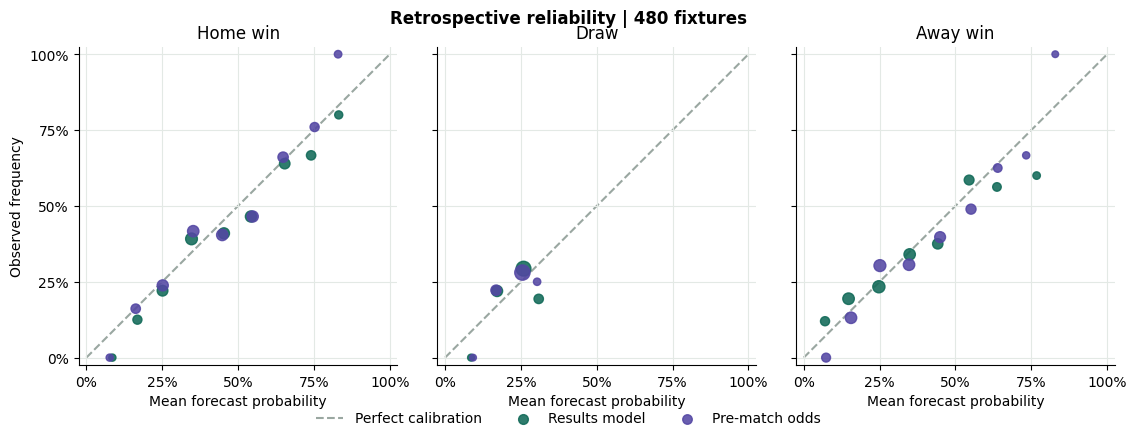

In [9]:
figure = calibration_plot(retrospective_report)
plt.show()

## Make a prediction

In [10]:
HOME_TEAM = "Arsenal"
AWAY_TEAM = "Chelsea"
MATCH_DATE = fixtures[-1].date + timedelta(days=1)
DECIMAL_ODDS = None  # Optional home, draw, away decimal odds.

forecast = predictor.forecast(MATCH_DATE, HOME_TEAM, AWAY_TEAM)
probabilities = {"Results model": forecast.probabilities}
if DECIMAL_ODDS is not None:
    probabilities["Pre-match odds"] = MarketOdds(*DECIMAL_ODDS).probabilities

print(f"{forecast.home.name} vs {forecast.away.name} on {forecast.date}")
pick = {"H": forecast.home.name, "D": "Draw", "A": forecast.away.name}[forecast.prediction]
print(f"Top pick: {pick} ({max(forecast.probabilities):.1%})")
print(f"Trained on {forecast.training_matches:,} results through {forecast.trained_through}")
if forecast.actual:
    print(f"Final score {forecast.actual.home_goals}-{forecast.actual.away_goals}")
pd.DataFrame(probabilities, index=labels).round(3)

Arsenal vs Chelsea on 2026-11-09
Top pick: Arsenal (65.6%)
Trained on 6,364 results through 2026-11-08


,Results model
Home win,0.656
Draw,0.206
Away win,0.138


## Live gameweek scoreboard

This table shows how many matches have been forecast and scored. Scroll to **Upcoming match picks** for the predictions.

In [11]:
SCOREBOARD_DB = Path('C:/Users/adamj/OneDrive/Desktop/Premier-League-Match-Predictor-main/scoreboard.sqlite3')
scoreboard = read_scoreboard(SCOREBOARD_DB, 2026)
records = logged_forecasts(SCOREBOARD_DB, 2026)
if scoreboard.updated_at:
    print(f"Last synced {pd.Timestamp(scoreboard.updated_at):%Y-%m-%d %H:%M:%S UTC}")
    board = pd.read_csv(StringIO(scoreboard_csv(scoreboard)))
    active_weeks = board.loc[board["forecasted"].gt(0), [
        "gameweek", "scheduled", "forecasted", "scored", "paired",
        "paired_model_log_loss", "market_log_loss",
    ]]
    display(active_weeks.round(3))
    if records:
        issued = pd.DataFrame(records)
        recent_gameweeks = sorted(issued["gameweek"].dropna().unique())[-3:]
        issued = issued.loc[issued["gameweek"].isin(recent_gameweeks)].sort_values(
            ["gameweek", "kickoff_at_issue", "home"],
        ).reset_index(drop=True)
        probability_columns = ["p_home", "p_draw", "p_away"]
        issued[probability_columns] = pd.DataFrame(issued["probabilities"].tolist(), index=issued.index)
else:
    print("No prospective forecasts logged yet. Run a scoreboard sync to start.")

Last synced 2026-11-19 01:16:15 UTC


,gameweek,scheduled,forecasted,scored,paired,paired_model_log_loss,market_log_loss
10,11,10,10,0,0,NaN,NaN
11,12,10,10,0,0,NaN,NaN
12,13,10,10,0,0,NaN,NaN


## Save the retrospective results

In [12]:
EXPORT_BACKTEST = False
if EXPORT_BACKTEST:
    Path("notebook_backtest.csv").write_text(backtest_csv(full_report, include_market=True), encoding="utf-8", newline="")

## Upcoming match picks

Each top pick is the most likely outcome in the locked forecast. A pick can be a club or a draw.

In [13]:
if records and not issued.empty:
    kickoff = pd.to_datetime(issued["current_kickoff"], utc=True)
    summary = issued.loc[issued["eligible"] & kickoff.gt(utc_now())].copy()
    columns = ["p_home", "p_draw", "p_away"]
    outcomes = summary[columns].idxmax(axis=1)
    summary["Top pick"] = summary["home"].where(outcomes.eq("p_home"), summary["away"]).where(
        outcomes.ne("p_draw"), "Draw"
    )
    summary["Pick probability"] = summary[columns].max(axis=1).map("{:.1%}".format)
    if summary.empty:
        print("There are no upcoming picks in the displayed gameweeks.")
    else:
        display(summary.rename(columns={"gameweek": "Gameweek", "home": "Home", "away": "Away"})[
            ["Gameweek", "Home", "Away", "Top pick", "Pick probability"]
        ].reset_index(drop=True))
else:
    print("No live picks have been logged yet.")

,Gameweek,Home,Away,Top pick,Pick probability
0,11,Manchester City,Fulham,Manchester City,70.1%
1,11,Aston Villa,Sunderland,Aston Villa,58.9%
2,11,Bournemouth,Nottingham Forest,Bournemouth,53.1%
3,11,Chelsea,Leeds United,Chelsea,51.4%
4,11,Coventry City,Crystal Palace,Coventry City,40.3%
5,11,Tottenham Hotspur,Ipswich Town,Tottenham Hotspur,57.0%
6,11,Newcastle United,Arsenal,Arsenal,60.8%
7,11,Hull City,Brighton and Hove Albion,Brighton and Hove Albion,55.3%
8,11,Liverpool,Manchester United,Liverpool,51.0%
9,11,Brentford,Everton,Brentford,43.9%


## Predict the 2026/27 season

Use the local schedule offline or set `LIVE_SEASON` to fetch the official dates and results. Upcoming rows are projections from the latest snapshot. Both the forecast timestamp and the last result date are printed and recorded in the export. Dates can change. [Official fixture list](https://www.premierleague.com/en/news/4675097/all-380-fixtures-for-season-202627-premier-league-season)

In [14]:
LIVE_SEASON = False
SEASON_FIXTURES = Path("fixtures_2026_27.csv")
SAVE_SEASON_PREDICTIONS = False
as_of = utc_now()

if LIVE_SEASON:
    official = official_schedule(2026)
    _, confirmed = official_history(2026, official, fixtures, utc_now())
    schedule = tuple(ScheduledMatch(match.day, match.home, match.away) for match in official if match.day)
    season_predictor = Predictor(confirmed, model=selected_model)
    as_of = utc_now()
elif SEASON_FIXTURES.is_file():
    schedule = load_schedule(SEASON_FIXTURES)
    season_predictor = predictor
else:
    schedule = ()
    print("Set LIVE_SEASON = True or supply a local fixtures_2026_27.csv.")

if schedule:
    season_predictions = pd.read_csv(StringIO(season_csv(forecast_season(season_predictor, schedule, as_of=as_of))))
    upcoming = season_predictions.loc[season_predictions["status"].eq("Upcoming")]
    print(f"Last updated {as_of:%Y-%m-%d %H:%M UTC} | Results through {season_predictor.fixtures[-1].date}")
    print(f"{len(season_predictions)} fixtures | {len(upcoming)} upcoming")
    if SAVE_SEASON_PREDICTIONS:
        season_predictions.to_csv("season_2026_27_predictions.csv", index=False)
    display(upcoming[["date", "home_team", "away_team", "pick", "p_home", "p_draw", "p_away"]].head(10))

Last updated 2026-11-19 01:43 UTC | Results through 2026-11-08


380 fixtures | 280 upcoming


,date,home_team,away_team,pick,p_home,p_draw,p_away
100,2026-11-21,Aston Villa,Sunderland,Aston Villa,0.589014,0.227083,0.183903
101,2026-11-21,Bournemouth,Nottingham Forest,Bournemouth,0.531000,0.247708,0.221291
102,2026-11-21,Chelsea,Leeds United,Chelsea,0.513782,0.253662,0.232556
103,2026-11-21,Coventry City,Crystal Palace,Coventry City,0.403420,0.276918,0.319662
104,2026-11-21,Manchester City,Fulham,Manchester City,0.700577,0.186338,0.113085
105,2026-11-21,Newcastle United,Arsenal,Arsenal,0.193229,0.199107,0.607663
106,2026-11-21,Tottenham Hotspur,Ipswich Town,Tottenham Hotspur,0.570398,0.237226,0.192375
107,2026-11-22,Hull City,Brighton and Hove Albion,Brighton and Hove Albion,0.206876,0.239762,0.553362
108,2026-11-22,Liverpool,Manchester United,Liverpool,0.509579,0.255632,0.234789
109,2026-11-23,Brentford,Everton,Brentford,0.439333,0.276719,0.283948


## Full-season picks

This table shows the model's pick for every fixture without a recorded result. Use `TEAM_FILTER` to see just one club. Run the season cell above again after refreshing the results.

In [15]:
TEAM_FILTER = None  # Example: "Arsenal"
if not schedule:
    print("Load the season schedule in Predict the 2026/27 season.")
else:
    future_picks = season_predictions.loc[season_predictions["status"].ne("Completed")].copy()
    future_picks["Pick probability"] = future_picks[["p_home", "p_draw", "p_away"]].max(axis=1).map("{:.1%}".format)
    full_season_picks = future_picks.rename(columns={
        "date": "Date", "home_team": "Home", "away_team": "Away", "pick": "Top pick",
    })[["Date", "Home", "Away", "Top pick", "Pick probability"]].reset_index(drop=True)
    shown = full_season_picks
    if TEAM_FILTER:
        name = TEAM_FILTER.strip().casefold()
        shown = shown.loc[shown["Home"].str.casefold().eq(name) | shown["Away"].str.casefold().eq(name)]
    print(f"{len(shown)} upcoming picks shown from {len(season_predictions)} season fixtures.")
    with pd.option_context("display.max_rows", None):
        display(shown.reset_index(drop=True))

280 upcoming picks shown from 380 season fixtures.


,Date,Home,Away,Top pick,Pick probability
0,2026-11-21,Aston Villa,Sunderland,Aston Villa,58.9%
1,2026-11-21,Bournemouth,Nottingham Forest,Bournemouth,53.1%
2,2026-11-21,Chelsea,Leeds United,Chelsea,51.4%
3,2026-11-21,Coventry City,Crystal Palace,Coventry City,40.3%
4,2026-11-21,Manchester City,Fulham,Manchester City,70.1%
5,2026-11-21,Newcastle United,Arsenal,Arsenal,60.8%
6,2026-11-21,Tottenham Hotspur,Ipswich Town,Tottenham Hotspur,57.0%
7,2026-11-22,Hull City,Brighton and Hove Albion,Brighton and Hove Albion,55.3%
8,2026-11-22,Liverpool,Manchester United,Liverpool,51.0%
9,2026-11-23,Brentford,Everton,Brentford,43.9%


## Projected final standings

**Saved 2026/27 projection using results through November 8, 2026.**

| Rank | Club | Played | Points so far | Projected final points |
| ---: | --- | ---: | ---: | ---: |
| 1 | Arsenal | 10 | 27 | 86.4 |
| 2 | Manchester City | 10 | 21 | 78.4 |
| 3 | Brighton and Hove Albion | 10 | 22 | 68.9 |
| 4 | Liverpool | 10 | 18 | 66.7 |
| 5 | Bournemouth | 10 | 15 | 58.9 |
| 6 | Chelsea | 10 | 16 | 58.7 |
| 7 | Aston Villa | 10 | 13 | 55.5 |
| 8 | Everton | 10 | 16 | 53.9 |
| 9 | Brentford | 10 | 14 | 52.7 |
| 10 | Leeds United | 10 | 14 | 51.4 |
| 11 | Manchester United | 10 | 8 | 50.8 |
| 12 | Newcastle United | 10 | 12 | 46.5 |

In [16]:
POINT_ADJUSTMENTS = {}  # Example: {"Club name": -3}
if not schedule:
    print("Load the season schedule to project the standings.")
else:
    completed = season_predictions["status"].eq("Completed")
    team_rows = []
    for side, win in (("home", "H"), ("away", "A")):
        points = season_predictions["actual"].map({win: 3, "D": 1}).fillna(0)
        expected = 3 * season_predictions[f"p_{side}"] + season_predictions["p_draw"]
        team_rows.append(pd.DataFrame({
            "Club": season_predictions[f"{side}_team"],
            "Played": completed.astype(int),
            "Points so far": points.where(completed, 0).astype(int),
            "Remaining": (~completed).astype(int),
            "Expected points remaining": expected.where(~completed, 0),
        }))

    projected_standings = pd.concat(team_rows).groupby("Club", as_index=False).sum()
    projected_standings["Points so far"] += projected_standings["Club"].map(POINT_ADJUSTMENTS).fillna(0).astype(int)
    projected_standings["Projected final points"] = (
        projected_standings["Points so far"] + projected_standings["Expected points remaining"]
    )
    projected_standings = projected_standings.sort_values(
        ["Projected final points", "Club"], ascending=[False, True],
    ).reset_index(drop=True)
    projected_standings.insert(0, "Rank", range(1, len(projected_standings) + 1))
    display(projected_standings.round(1))

,Rank,Club,Played,Points so far,Remaining,Expected points remaining,Projected final points
0,1,Arsenal,10,27,28,59.4,86.4
1,2,Manchester City,10,21,28,57.4,78.4
2,3,Brighton and Hove Albion,10,22,28,46.9,68.9
3,4,Liverpool,10,18,28,48.7,66.7
4,5,Bournemouth,10,15,28,43.9,58.9
5,6,Chelsea,10,16,28,42.7,58.7
6,7,Aston Villa,10,13,28,42.5,55.5
7,8,Everton,10,16,28,37.9,53.9
8,9,Brentford,10,14,28,38.7,52.7
9,10,Leeds United,10,14,28,37.4,51.4
